# 02 — Price Analysis

Loads cleaned data and time-series features, then produces price history plots,
change distribution charts, and rolling volatility visualisations.

**Prerequisites** (run in order if outputs are missing):
- `scripts/preprocess.py` → `../data/processed/cleaned_data.csv`
- `scripts/build_timeseries.py` → `../data/processed/series_*.csv`
- `scripts/generate_queries.py` → `../data/features/`

**Outputs**
- `../data/figures/top5_price_histories.png`
- `../data/figures/pct_change_distribution.png`
- `../data/figures/days_since_previous_dist.png`
- `../data/figures/rolling_volatility_sample.png`

In [1]:
import sys
import os
import warnings

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
import numpy as np

warnings.filterwarnings('ignore')

sys.path.insert(0, '..')

from src.data.loader import load_raw
from src.data.preprocessing import preprocess, load_cleaned
from src.timeseries.builder import build_time_series, load_series

os.makedirs('../data/figures', exist_ok=True)
os.makedirs('../data/processed', exist_ok=True)

print('Imports OK')

Imports OK


## 1. Load Cleaned Data

In [2]:
cleaned_path = '../data/processed/cleaned_data.csv'

if os.path.exists(cleaned_path):
    print(f'Loading cleaned data from {cleaned_path} ...')
    df_clean = load_cleaned(cleaned_path)
    print(f'Cleaned data: {df_clean.shape[0]:,} rows × {df_clean.shape[1]} columns')
else:
    print(f'{cleaned_path} not found — running preprocessing inline ...')
    pointer_file = '../data/raw/DATA_PATH.txt'
    try:
        with open(pointer_file, 'r', encoding='utf-8') as fh:
            raw_csv_path = fh.read().strip()
    except FileNotFoundError:
        raise FileNotFoundError(
            f'DATA_PATH.txt not found at {pointer_file}.\n'
            'Run 01_dataset_profiling.ipynb first or create the file manually.'
        )
    df_raw = load_raw(raw_csv_path)
    df_clean, log = preprocess(df_raw)
    print(log.summary())
    print(f'Cleaned data: {df_clean.shape[0]:,} rows × {df_clean.shape[1]} columns')

Loading cleaned data from ../data/processed/cleaned_data.csv ...


Cleaned data: 33,869 rows × 25 columns


## 2. Load (or Build) Time-Series Catalogue

In [3]:
processed_dir = '../data/processed'
series_summary_path = os.path.join(processed_dir, 'series_summary.csv')

if os.path.exists(series_summary_path):
    print('Loading time-series catalogue from disk ...')
    catalogue = load_series(processed_dir)
else:
    print('series_summary.csv not found — building catalogue inline (may take a minute) ...')
    catalogue = build_time_series(df_clean)

series_df = catalogue.series_df
summary_df = catalogue.summary

print(f'Series observations : {len(series_df):,}')
print(f'PM pairs total      : {len(summary_df):,}')
print(f'Usable PM pairs     : {len(catalogue.usable_pairs):,}')
print(f'\nSeries columns: {list(series_df.columns)}')

Loading time-series catalogue from disk ...


Series observations : 33,869
PM pairs total      : 6,002
Usable PM pairs     : 2,268

Series columns: ['product_id', 'merchant', 'observed_at', 'price', 'price_min', 'price_max', 'is_sale', 'availability', 'condition', 'offer', 'product_name', 'brand', 'manufacturer', 'manufacturer_number', 'category', 'source_url', 'observation_index', 'previous_price', 'absolute_change', 'percentage_change', 'days_since_previous']


## 3. Summary Statistics for All PM Pairs

In [4]:
print('=== Summary Statistics for All PM Pairs ===')
display(
    summary_df.describe()
    .loc[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]
    .T
    .style.format('{:.2f}')
)

print('\nTop 10 PM pairs by observation count:')
display(
    summary_df
    .nlargest(10, 'n_observations')
    [['product_id', 'merchant', 'n_observations', 'price_min', 'price_max', 'price_mean']]
    .reset_index(drop=True)
)

=== Summary Statistics for All PM Pairs ===


,count,mean,std,min,25%,50%,75%,max
n_observations,6002.00,5.64,7.04,1.00,1.00,2.00,9.00,202.00
price_min,6002.00,437.71,950.15,1.00,74.99,171.69,449.95,19999.99
price_max,6002.00,486.13,1095.38,1.50,79.99,198.00,494.98,26871.00
price_mean,6002.00,462.20,992.23,1.50,79.95,181.61,469.99,19999.99
price_std,3657.00,34.87,331.65,0.00,0.00,2.43,17.32,15341.29
price_median,6002.00,461.96,992.02,1.50,79.95,179.99,472.81,19999.99
n_sale_observations,6002.00,0.45,1.76,0.00,0.00,0.00,0.00,32.00
span_days,6002.00,127.55,202.48,0.00,0.00,20.17,220.31,1365.00
price_range,6002.00,48.42,487.78,0.00,0.00,0.00,13.00,26582.76



Top 10 PM pairs by observation count:


,product_id,merchant,n_observations,price_min,price_max,price_mean
0,AVphcCmRLJeJML43a6Mh,Amazon.com,202,259.99,389.99,387.8593
1,AVpflKqwLJeJML43_2MI,LG.com,112,2999.99,6999.99,5285.7043
2,AVpfpK8KLJeJML43BCuD,Amazon.com,78,129.99,129.99,129.9900
3,AVpfAs_-ilAPnD_xS-SU,bhphotovideo.com,57,2398.00,5010.50,3788.9386
4,AV1YHuUN-jtxr-f31Ndf,bhphotovideo.com,49,1242.95,2596.00,1975.5296
5,AVqKqTgmQMlgsOJE6bhX,bhphotovideo.com,48,699.00,1148.99,853.2665
6,AVpe6fRRilAPnD_xQvwN,Amazon.com,48,68.99,84.95,80.8110
7,AVpfg618LJeJML43-j8w,Microsoft,45,59.99,59.99,59.9900
8,AV1YFZVDvKc47QAVgp7V,bhphotovideo.com,44,133.99,1163.50,676.7018
9,AV1YCh1FvKc47QAVgpNt,bhphotovideo.com,43,1437.50,3749.00,2266.0119


## 4. Price History — Top-5 Most-Observed PM Pairs

Top-5 PM pairs selected for price history plots:


,product_id,merchant
0,AVphcCmRLJeJML43a6Mh,Amazon.com
1,AVpflKqwLJeJML43_2MI,LG.com
2,AVpfpK8KLJeJML43BCuD,Amazon.com
3,AVpfAs_-ilAPnD_xS-SU,bhphotovideo.com
4,AV1YHuUN-jtxr-f31Ndf,bhphotovideo.com


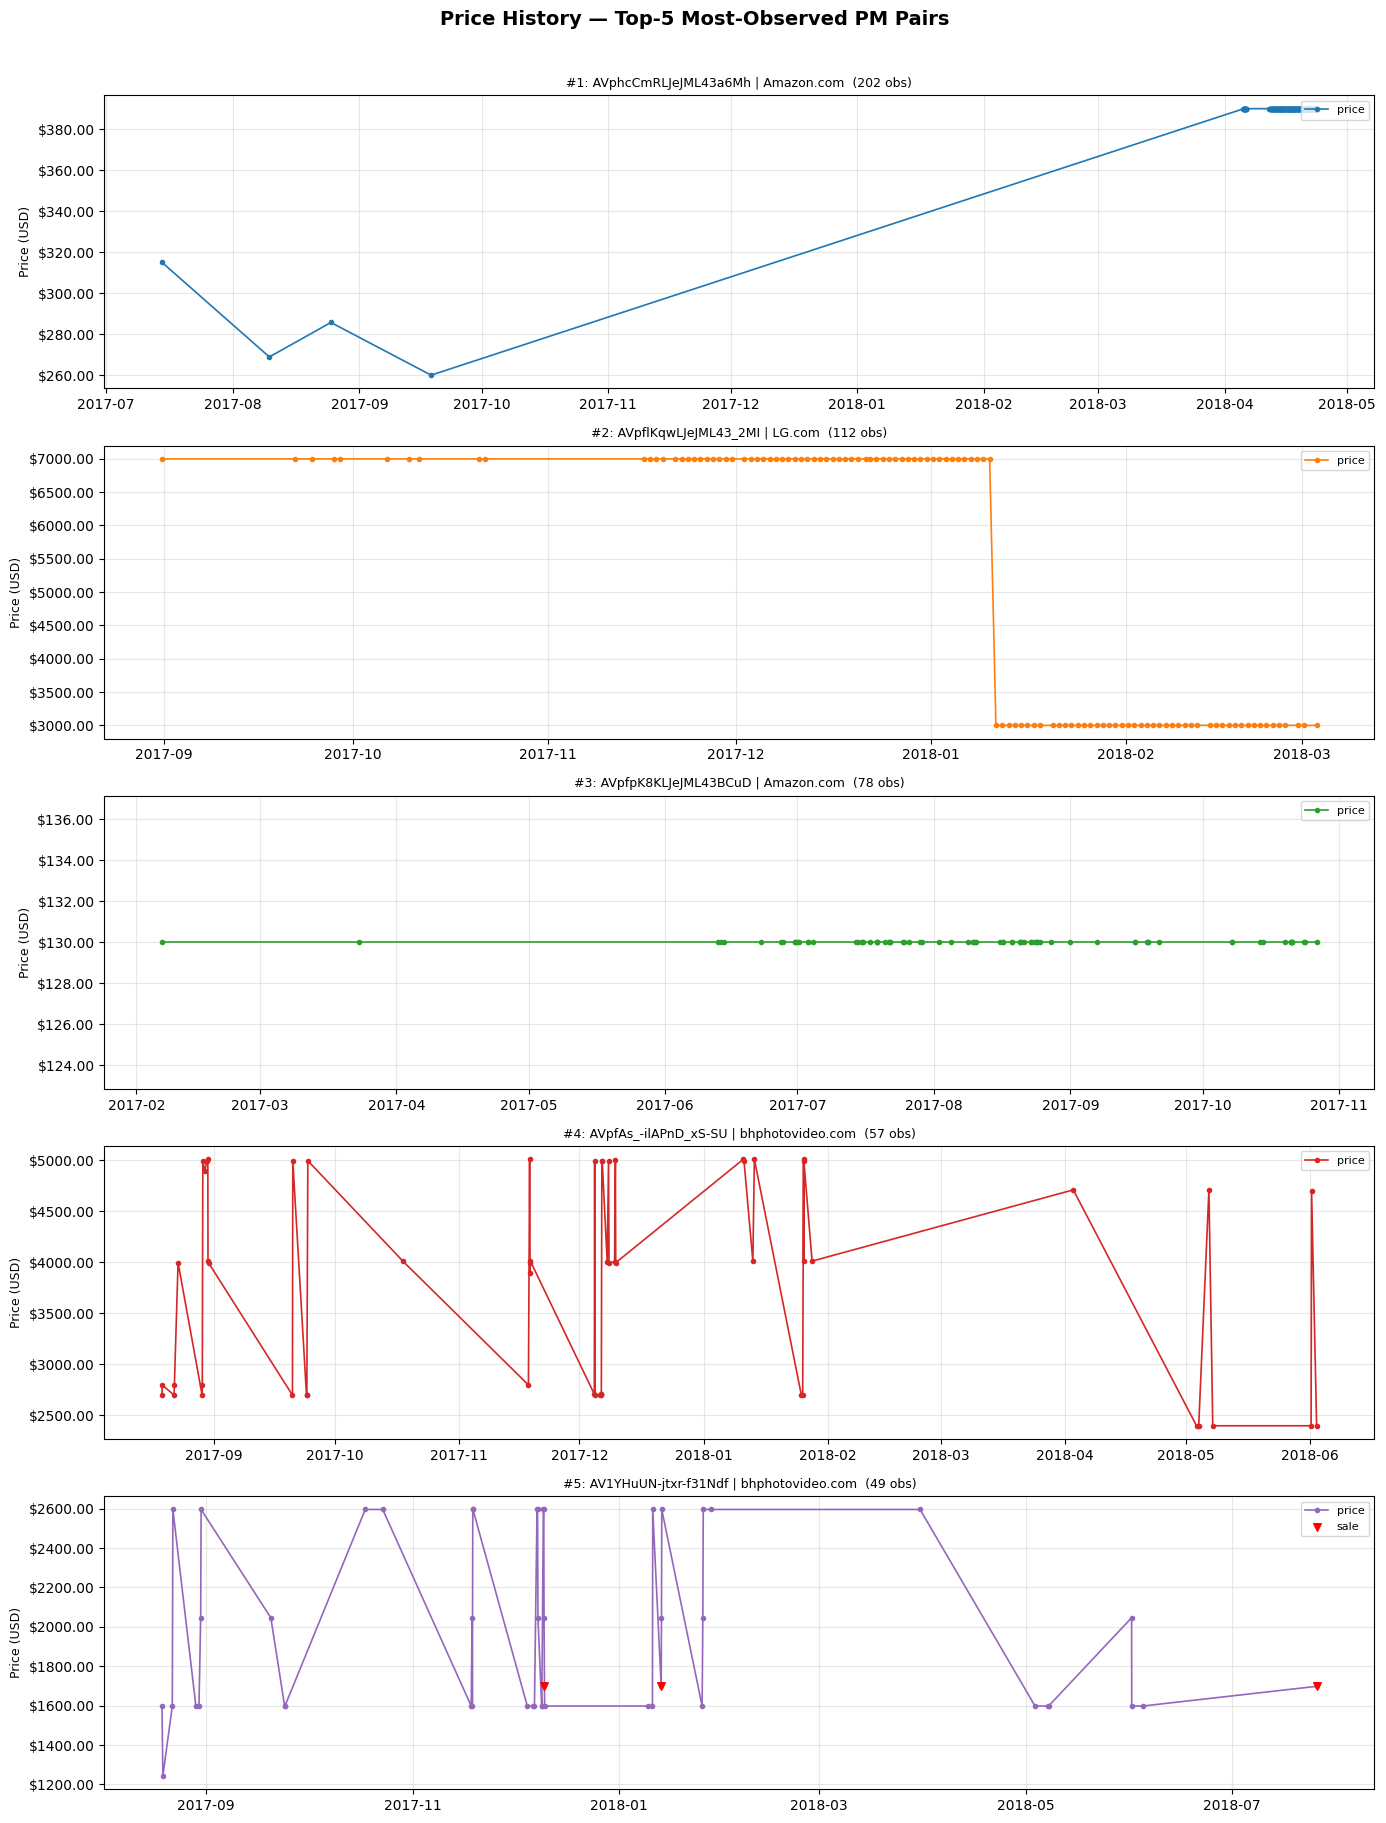

Saved: ../data/figures/top5_price_histories.png


In [5]:
top5 = summary_df.nlargest(5, 'n_observations')[['product_id', 'merchant']].reset_index(drop=True)
print('Top-5 PM pairs selected for price history plots:')
display(top5)

fig, axes = plt.subplots(5, 1, figsize=(14, 18), sharex=False)

for i, row in top5.iterrows():
    pid = row['product_id']
    merch = row['merchant']
    subset = (
        series_df[
            (series_df['product_id'] == pid) &
            (series_df['merchant'] == merch)
        ]
        .sort_values('observed_at')
    )

    ax = axes[i]
    ax.plot(
        pd.to_datetime(subset['observed_at']),
        subset['price'],
        marker='o', markersize=3, linewidth=1.2,
        color=plt.cm.tab10.colors[i],
        label='price'
    )

    # Mark sale observations if column exists
    if 'is_sale' in subset.columns:
        sale_mask = subset['is_sale'].fillna(False).astype(bool)
        if sale_mask.any():
            sale_sub = subset[sale_mask]
            ax.scatter(
                pd.to_datetime(sale_sub['observed_at']),
                sale_sub['price'],
                color='red', zorder=5, s=30, label='sale', marker='v'
            )

    short_id = str(pid)[:30] + ('...' if len(str(pid)) > 30 else '')
    ax.set_title(f'#{i+1}: {short_id} | {merch}  ({len(subset)} obs)', fontsize=9)
    ax.set_ylabel('Price (USD)', fontsize=9)
    ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('$%.2f'))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    ax.xaxis.set_major_locator(mdates.AutoDateLocator())
    ax.legend(fontsize=8, loc='upper right')
    ax.grid(alpha=0.3)

fig.suptitle('Price History — Top-5 Most-Observed PM Pairs', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('../data/figures/top5_price_histories.png', dpi=100, bbox_inches='tight')
plt.show()
print('Saved: ../data/figures/top5_price_histories.png')

## 5. Distribution of `percentage_change` Values

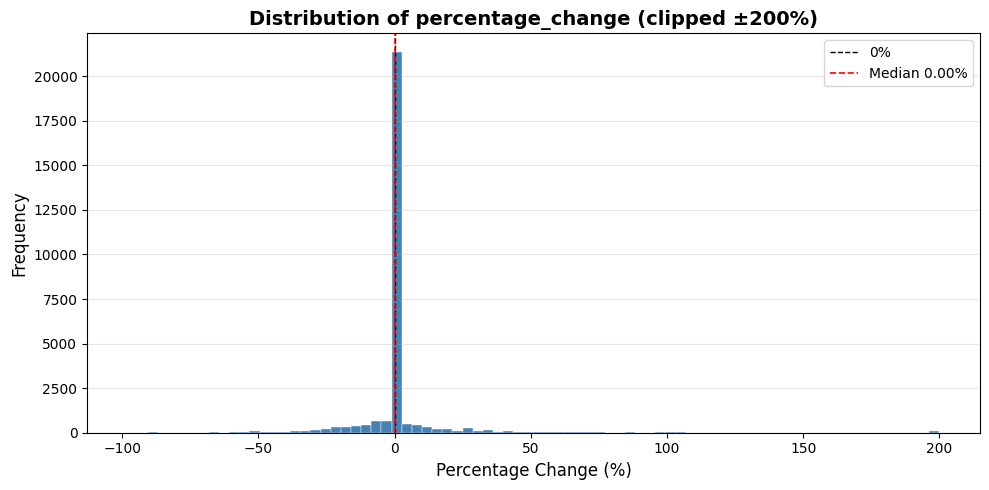

Saved: ../data/figures/pct_change_distribution.png

percentage_change stats:
count    27867.000000
mean         3.191553
std        119.734470
min        -97.999600
25%          0.000000
50%          0.000000
75%          0.000000
max       9900.000000


In [6]:
pct_col = next(
    (c for c in series_df.columns if 'pct' in c.lower() or 'percentage' in c.lower()),
    None
)

if pct_col is None:
    print('percentage_change column not found in series_df.')
    print('Available columns:', list(series_df.columns))
else:
    pct_vals = series_df[pct_col].dropna()
    # Clip to ±200% for readability
    pct_clip = pct_vals.clip(-200, 200)

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.hist(pct_clip, bins=80, color='steelblue', edgecolor='white', linewidth=0.3)
    ax.axvline(0, color='black', linewidth=1, linestyle='--', label='0%')
    ax.axvline(pct_vals.median(), color='red', linewidth=1.2, linestyle='--',
               label=f'Median {pct_vals.median():.2f}%')
    ax.set_xlabel('Percentage Change (%)', fontsize=12)
    ax.set_ylabel('Frequency', fontsize=12)
    ax.set_title(f'Distribution of {pct_col} (clipped ±200%)', fontsize=14, fontweight='bold')
    ax.legend(fontsize=10)
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.savefig('../data/figures/pct_change_distribution.png', dpi=100, bbox_inches='tight')
    plt.show()
    print(f'Saved: ../data/figures/pct_change_distribution.png')
    print(f'\n{pct_col} stats:')
    print(pct_vals.describe().to_string())

## 6. Distribution of `days_since_previous`

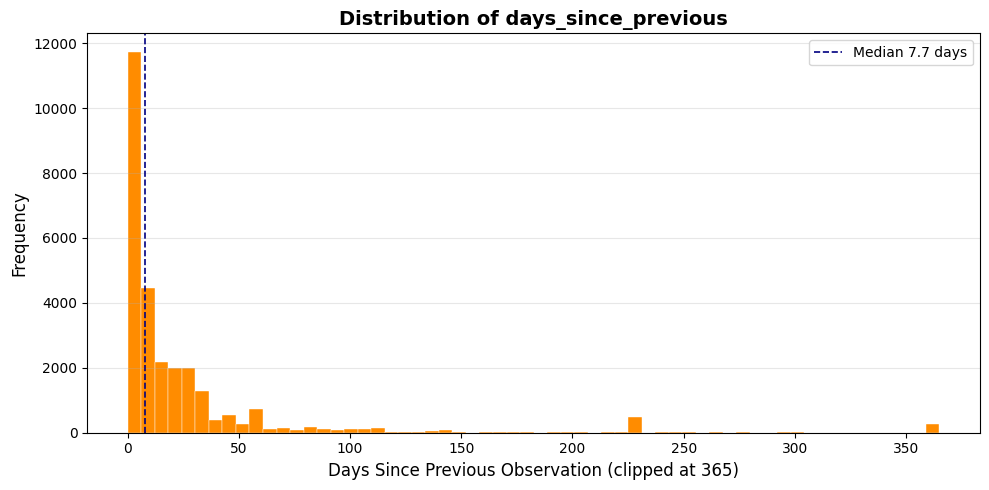

Saved: ../data/figures/days_since_previous_dist.png

days_since_previous stats:
count    27867.000000
mean        27.471923
std         66.851500
min          0.041667
25%          1.958333
50%          7.708333
75%         26.083333
max       1365.000000


In [7]:
days_col = next(
    (c for c in series_df.columns if 'days_since' in c.lower()),
    None
)

if days_col is None:
    print('days_since_previous column not found in series_df.')
    print('Available columns:', list(series_df.columns))
else:
    days_vals = series_df[days_col].dropna()
    days_clip = days_vals.clip(0, 365)

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.hist(days_clip, bins=60, color='darkorange', edgecolor='white', linewidth=0.3)
    ax.axvline(days_vals.median(), color='navy', linewidth=1.2, linestyle='--',
               label=f'Median {days_vals.median():.1f} days')
    ax.set_xlabel('Days Since Previous Observation (clipped at 365)', fontsize=12)
    ax.set_ylabel('Frequency', fontsize=12)
    ax.set_title(f'Distribution of {days_col}', fontsize=14, fontweight='bold')
    ax.legend(fontsize=10)
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.savefig('../data/figures/days_since_previous_dist.png', dpi=100, bbox_inches='tight')
    plt.show()
    print(f'Saved: ../data/figures/days_since_previous_dist.png')
    print(f'\n{days_col} stats:')
    print(days_vals.describe().to_string())

## 7. Rolling Volatility for a Sample Series

Sample pair: AVphcCmRLJeJML43a6Mh | Amazon.com  (202 obs)


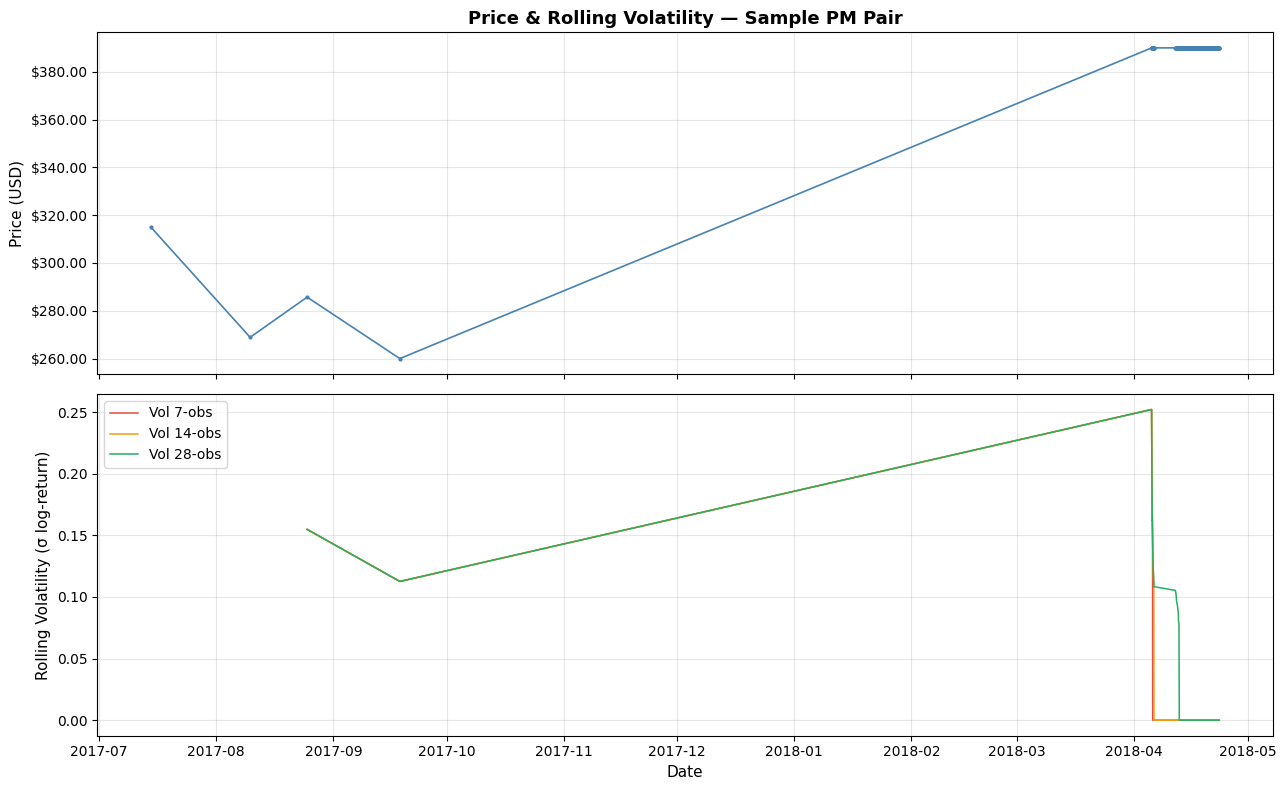

Saved: ../data/figures/rolling_volatility_sample.png


In [8]:
# Pick the PM pair with the most observations for a meaningful volatility plot
top_pair = summary_df.nlargest(1, 'n_observations').iloc[0]
pid_sample = top_pair['product_id']
merch_sample = top_pair['merchant']

sample = (
    series_df[
        (series_df['product_id'] == pid_sample) &
        (series_df['merchant'] == merch_sample)
    ]
    .sort_values('observed_at')
    .copy()
)

print(f'Sample pair: {pid_sample[:40]} | {merch_sample}  ({len(sample)} obs)')

# Compute rolling volatility inline if not already in series_df
sample['log_price'] = np.log(sample['price'].clip(lower=1e-9))
sample['log_diff'] = sample['log_price'].diff()
for w in [7, 14, 28]:
    col = f'rolling_vol_{w}'
    existing = f'rolling_volatility_{w}'
    if existing in sample.columns:
        sample[col] = sample[existing]
    else:
        sample[col] = sample['log_diff'].rolling(w, min_periods=2).std()

dates = pd.to_datetime(sample['observed_at'])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 8), sharex=True)

ax1.plot(dates, sample['price'], color='steelblue', linewidth=1.2, marker='o', markersize=2)
ax1.set_ylabel('Price (USD)', fontsize=11)
ax1.set_title(f'Price & Rolling Volatility — Sample PM Pair', fontsize=13, fontweight='bold')
ax1.yaxis.set_major_formatter(mticker.FormatStrFormatter('$%.2f'))
ax1.grid(alpha=0.3)

for w, color, label in [(7, '#e74c3c', '7-obs'), (14, '#f39c12', '14-obs'), (28, '#27ae60', '28-obs')]:
    col = f'rolling_vol_{w}'
    if col in sample.columns and sample[col].notna().any():
        ax2.plot(dates, sample[col], color=color, linewidth=1.1, label=f'Vol {label}')

ax2.set_ylabel('Rolling Volatility (σ log-return)', fontsize=11)
ax2.set_xlabel('Date', fontsize=11)
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
ax2.xaxis.set_major_locator(mdates.AutoDateLocator())
ax2.legend(fontsize=10)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('../data/figures/rolling_volatility_sample.png', dpi=100, bbox_inches='tight')
plt.show()
print('Saved: ../data/figures/rolling_volatility_sample.png')